# Feature Selection 

In [4]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.metrics import accuracy_score

RANDOM_STATE = 111

## 2. The protocol: nested cross-validation

Most selection methods have a setting we must choose — usually **k, the number of
features to keep**. Choosing k is part of the method, so it must be done **without
looking at the test data**. Nested cross-validation has two loops:

```
OUTER loop (5 folds) — answers "how good is the whole procedure?"
│
├── split the data: 4/5 outer-TRAINING, 1/5 outer-TEST (put aside, untouched)
│
├── INNER loop (4 folds, on the outer-training part only) — answers "which k?"
│     for every candidate k:
│         for every inner fold:
│             select k features on the inner-training part
│             train the classifier, measure accuracy on the inner-validation part
│         average the 4 validation accuracies
│     -> keep the k with the best average
│
├── redo the selection with that k on the WHOLE outer-training part
├── train the classifier on the outer-training part
└── measure accuracy ONCE on the outer-test fold
```

With 5 outer folds, the outer-training part is 4/5 of the data; splitting it into 4 inner
folds makes each inner-validation fold the same size as one outer block (60 samples here).
This 5 + 4 scheme is the one you will use in your project.

At the end we have **5 test accuracies**, one per outer fold: their mean ± std is the
performance estimate. Two things to keep in mind:

- the test fold is used **only once**, after every choice has been made;
- each outer fold can choose a **different k** and a **different set of features**. That
  is fine: we are evaluating the *procedure* ("select with method M, choosing k by inner
  CV"), not one particular feature list.

The same outer folds are used for every method, so all comparisons are **paired**.

In [8]:
import pandas as pd

X=pd.read_csv('/home/um40/LB2_project_Group_1/Feature_Selection/feature.csv')
# X=df.drop(columns='id',axis=1)

X.sort_values(by='id', inplace=True)

df=pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv',sep='\t')

df = df.sort_values(by='ID')

y= df['class']
X= X.drop(columns='id', axis=1)
fold= df['fold']

feature_names=X.columns.to_list()




K_GRID=[len(feature_names)//4,len(feature_names)//3,len(feature_names)//2,len(feature_names)]
C_GRID=[1,4,10,16]


GRID=[]
for k in K_GRID:
    for c in C_GRID:
        GRID.append((k,c,np.round(0.5/k,4))) 
        GRID.append((k,c,np.round(1/k,4))) 
        GRID.append((k,c,np.round(2/k,4))) 
        GRID.append((k,c,np.round(4/k,4))) 

### Building block 1: train and test a classifier

Logistic regression works better when features are on the same scale, so we standardise
them (mean 0, standard deviation 1). The **mean and standard deviation are learned on the
training data only**, and then applied, unchanged, to the test data. Learning them on all
the data would let the test samples influence the model.

In [39]:


def train_and_test(X_train, y_train, X_test, y_test, new_model):
    # train a classifier on (X_train, y_train) and return its accuracy on (X_test, y_test)
    
    if X_train.shape[1] == 0:
        # no feature selected: the best we can do is predict the most frequent class
        majority = np.bincount(y_train).argmax()
        return np.mean(y_test == majority)
    # NB: this previous part is just for Lasso

    # 1. learn the scaling (mean, std of each column) on the TRAINING data only
    scaler = StandardScaler().fit(X_train) # --> zeta scores = subtract the mean and divide by std (dependency from data, we compute mean & std on training deta => NOT USE TEST DATA TO COMPUTE THESE METRICS)
    # 2. train the classifier on the scaled training data
    model = new_model()
    model.fit(scaler.transform(X_train), y_train)
    # 3. scale the test data with the SAME mean and std, predict, measure accuracy
    y_pred = model.predict(scaler.transform(X_test))
    return accuracy_score(y_test, y_pred)

### Building block 2: the inner loop — choose a setting

Given **one outer-training set**, try every candidate setting (e.g. every k) with a
4-fold cross-validation *inside* it, and return the setting with the best mean
validation accuracy.

A selection method is just a function `select(X_train, y_train, setting)` that returns
the **indices of the columns to keep**. It only ever receives training data.

In [40]:
def choose_setting(select, grid, X, y, new_model,test_fold):
    # inner cross-validation on (X_train, y_train) only; returns the best setting
    # and the mean validation accuracy of every setting
    train_fold=[[k for k in range(1,6) if k!=test_fold]]
    mean_val_acc = {}
    for setting in grid: # --> for each set of hyperparam values in the grid
        val_accs = []
        for j in train_fold:

            in_val=fold[fold==j].index.to_list()
            in_train=fold[(fold!=j) &( fold>0)].index.to_list()
    
            # selection sees the inner-training part only
            cols = select(X.iloc[in_train], y.iloc[in_train], setting) #--> select the best features
            acc = train_and_test(X.iloc[in_train][:, cols], y.iloc[in_train],
                                 X.iloc[in_val][:, cols],   y.iloc[in_val], new_model) #--> train a new model with the subset of best features, then test it on validation fold
            val_accs.append(acc)
        mean_val_acc[setting] = np.mean(val_accs)

    best = max(mean_val_acc, key=mean_val_acc.get)   # ties -> the first (smallest) one
    # if we have two combination of features with same accuracy, always choose the one with fewer features (= less model's params, less overfit)
    return best, mean_val_acc

### Building block 3: the outer loop — nested cross-validation

For each outer fold: inner loop → redo selection on the whole outer-training part →
train → test once. We also record which features were selected, so that later we can
check them against the hidden answer.

In [42]:
results = []   # one entry per method

def nested_cv(name, family, select, grid, new_model,X,y,fold,verbose=True, store=True):
    
    start = time.time()
    test_accs, chosen, selected_sets, inner_curves = [], [], [], []
    # selected_sets --> selected set of feature for each fold (?)

    for i in range(1,6):

        test_idx=fold[fold==i].index.to_list()
        train_idx=fold[(fold!=i) &( fold>0)].index.to_list()


        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]

        # STEP 1 - inner loop: choose the setting using the training part only
        if len(grid) == 1:
            best, curve = grid[0], {}          # nothing to choose --> test on user input (in this case the grid contains just one value)
        else:
            best, curve = choose_setting(select, grid, X, y, new_model,i) #--> choose best setting (= #best_features to keep) on TRAIN SET

        # STEP 2 - redo the selection on the whole outer-training part
        cols = select(X_train, y_train, best) #--> given the #best_features (just a number!), select which are the #best most significant features on TRAIN TEST

        # STEP 3 - train on the outer-training part, test ONCE on the outer-test fold
        acc = train_and_test(X_train[:, cols], y_train, X_test[:, cols], y_test, new_model) #--> train a new model with the subset of best features, then test it on validation fold

        test_accs.append(acc)
        chosen.append(best)
        selected_sets.append(set(feature_names[cols]))
        inner_curves.append(curve)
        if verbose:
            print(f"  outer fold {fold}: chosen setting = {best:<5}  "
                  f"features kept = {len(cols):2d}   test accuracy = {acc:.3f}")

    seconds = time.time() - start
    test_accs = np.array(test_accs)
    if verbose:
        print(f"{name}: {test_accs.mean():.3f} ± {test_accs.std():.3f}   ({seconds:.1f}s)\n")

    entry = dict(method=name, family=family, chosen=chosen,
                 k=[len(s) for s in selected_sets], accuracy=test_accs.mean(),
                 std=test_accs.std(), seconds=seconds, fold_accs=test_accs,
                 sets=selected_sets, inner_curves=inner_curves, select=select, grid=grid)
    if store:
        results.append(entry)
    return entry

### Random-Forest importance, top-k

Train a Random Forest, rank features by Gini importance, keep the k best.

To keep the code simple, `select_rf` trains a new forest for **every** candidate k, even
though the ranking does not depend on k. Faster code would rank once per training set and
reuse the ranking for all k; the result would be the same. (The same is true for mutual
information.) This is why the Random Forest is the slowest method below.

In [ ]:
def select_rf(X_train, y_train, k):
    rf = RandomForestClassifier(n_estimators=100, random_state=0)
    rf.fit(X_train, y_train)
    ranking = np.argsort(rf.feature_importances_)[::-1]   # most important first (= gini importance)
    return ranking[:k]

rf = nested_cv("Embedded: RF importance", "embedded", select_rf, K_GRID)

In [30]:
test_idx=fold[fold==1].index.to_list()
train_idx=fold[(fold!=1) &( fold>0)].index.to_list()


X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]


in_val=fold[fold==2].index.to_list()
in_train=fold[(fold!=2) &( fold>0)].index.to_list()
    


# selection sees the inner-training part only
cols = select_rf(X.iloc[in_train], y.iloc[in_train], 10)
cols

array([ 2, 13,  0, 15,  1, 14, 16, 10,  9, 31])

OBSERVATION: the accuracy improves with respect all previous filters

### Analysis of the results (from the slides)

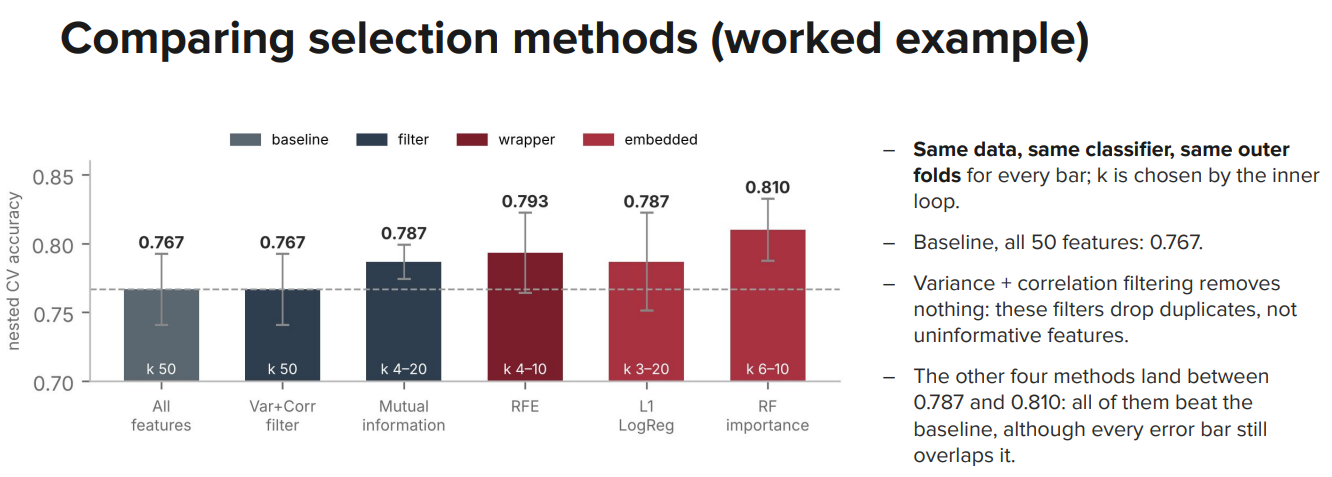

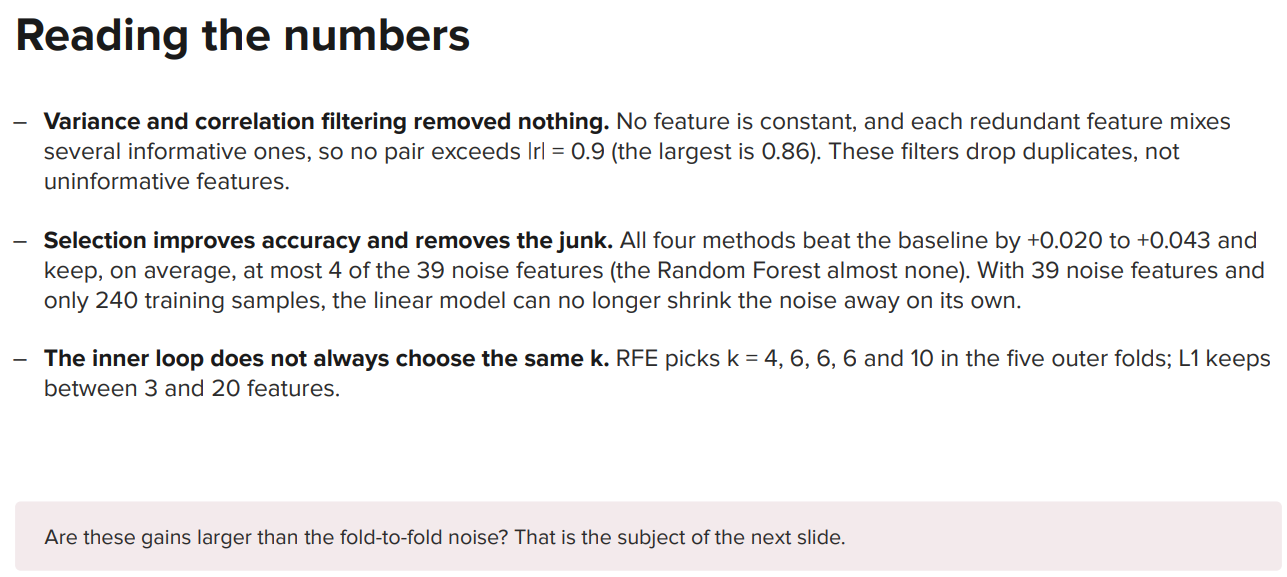

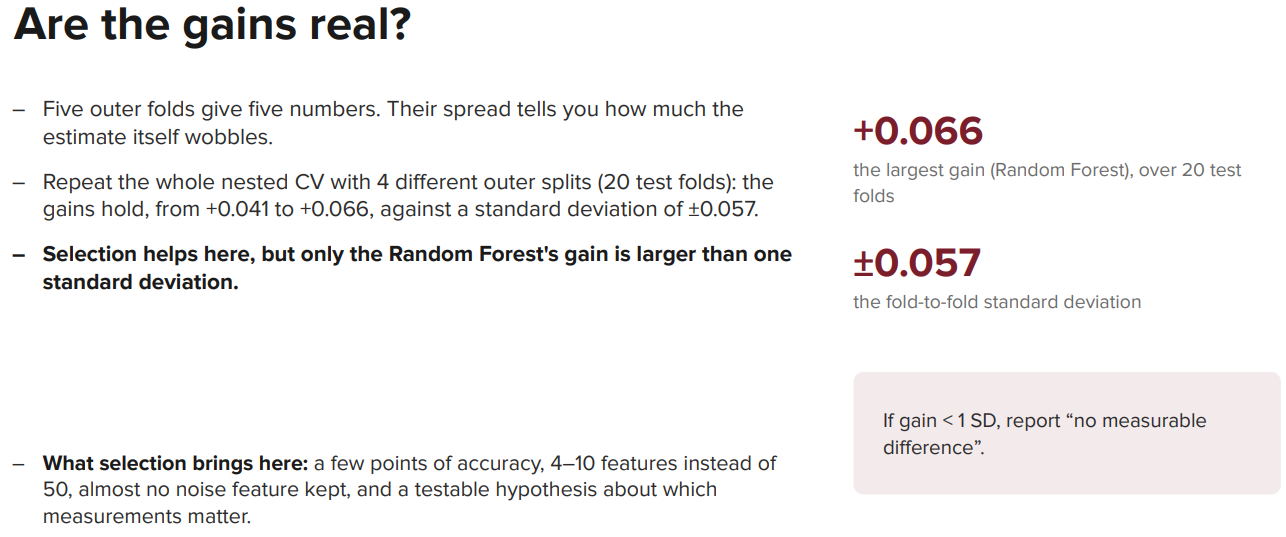

=> only the Random Forest's gain is larger than one
standard deviation, so RFE is the only method that "significantly improve" the performance while all the other remains similar to baseline (?)

## 6. The comparison table

Every row: same data, same classifier, same outer folds, k chosen by the inner loop.

The last two columns use the hidden answer: how many of the selected features carry
signal (informative or redundant), and how many are pure noise — averaged over the 5
outer folds.

In [ ]:
def signal_and_noise(selected):
    # how many selected features are signal (informative/redundant) and how many are noise
    roles = [true_role[feature_names == f][0] for f in selected]
    n_noise = roles.count("noise")
    return len(roles) - n_noise, n_noise

rows = []
for r in results:
    counts = [signal_and_noise(s) for s in r["sets"]]
    rows.append({
        "method":        r["method"],
        "family":        r["family"],
        "k per fold":    " ".join(str(k) for k in r["k"]),
        "accuracy":      r["accuracy"],
        "std":           r["std"],
        "delta":         r["accuracy"] - baseline["accuracy"],
        "seconds":       r["seconds"],
        "signal kept":   np.mean([c[0] for c in counts]),
        "noise kept":    np.mean([c[1] for c in counts]),
    })
table = pd.DataFrame(rows)
table.style.format({"accuracy": "{:.3f}", "std": "{:.3f}", "delta": "{:+.3f}",
                    "seconds": "{:.1f}", "signal kept": "{:.1f}", "noise kept": "{:.1f}"})

,method,family,k per fold,accuracy,std,delta,seconds,signal kept,noise kept
0,Baseline (all features),-,50 50 50 50 50,0.767,0.026,+0.000,0.0,11.0,39.0
1,Filter: variance + correlation,filter,50 50 50 50 50,0.767,0.026,+0.000,0.0,11.0,39.0
2,Filter: mutual information,filter,8 8 4 6 20,0.787,0.012,+0.020,21.1,6.2,3.0
3,Wrapper: RFE,wrapper,6 6 4 6 10,0.793,0.029,+0.027,12.1,5.0,1.4
4,Embedded: L1 logistic regression,embedded,7 3 3 20 3,0.787,0.036,+0.020,0.7,3.6,3.6
5,Embedded: RF importance,embedded,10 10 6 10 8,0.810,0.023,+0.043,30.5,8.6,0.2


In [ ]:
sel = table.iloc[1:]    # the selection methods, without the baseline
print(f"baseline (all {n_features} features)        : {baseline['accuracy']:.3f} ± {baseline['std']:.3f}")
print(f"selection methods, accuracy range  : {sel.accuracy.min():.3f} – {sel.accuracy.max():.3f}")
print(f"gain over the baseline, range      : {sel.delta.min():+.3f} – {sel.delta.max():+.3f}")
print(f"fold-to-fold std, range            : ±{sel['std'].min():.3f} – ±{sel['std'].max():.3f}")
print(f"slowest / fastest method           : "
      f"{sel.loc[sel.seconds.idxmax(), 'method']} ({sel.seconds.max():.1f}s) / "
      f"{sel.loc[sel.seconds.idxmin(), 'method']} ({sel.seconds.min():.1f}s)")

baseline (all 50 features)        : 0.767 ± 0.026
selection methods, accuracy range  : 0.767 – 0.810
gain over the baseline, range      : +0.000 – +0.043
fold-to-fold std, range            : ±0.012 – ±0.036
slowest / fastest method           : Embedded: RF importance (30.5s) / Filter: variance + correlation (0.0s)


### Reading the table

- **Compare each gain with the `std` column.** The fold-to-fold standard deviation tells
  you how much a 5-fold estimate wobbles on its own. A gain smaller than that wobble is not
  a measured improvement. Section 7 checks this more carefully.
- **Look at `k per fold`.** The inner loop does not always choose the same k: the "right"
  number of features is itself uncertain.
- **Look at `noise kept`.** This is the column we could never compute on real data. It
  tells us whether the methods find the junk — even when accuracy barely moves, because a
  linear model already copes with noise features by shrinking their coefficients towards
  zero.
- **Look at `seconds`.** Inside a nested CV every selection is repeated many times: with
  9 values of k, 5 outer folds and 4 inner folds, that is 5 × (9 × 4 + 1) = 185 selections
  per method. "Filters are cheap" is a rule of thumb, not a law: the k-nearest-neighbour
  estimator behind mutual information can cost more than RFE on a small linear model.

## 7. Are the gains real?

Five outer folds give five numbers per method. To get a more stable picture we **repeat
the whole nested cross-validation** with 4 different random outer splits (4 × 5 = 20
test folds per method), and compare each method with the baseline **fold by fold**, on
the same splits.

*This cell takes a few minutes on Colab.*

In [ ]:
N_REPEATS = 4
repeat_accs = {r["method"]: [] for r in results}

for repeat in range(N_REPEATS):
    outer_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=1000 + repeat)
    for r in results:
        e = nested_cv(r["method"], r["family"], r["select"], r["grid"],
                      outer=outer_r, verbose=False, store=False)
        repeat_accs[r["method"]].extend(e["fold_accs"])

In [ ]:
base_accs = np.array(repeat_accs["Baseline (all features)"])
rep_rows = []
for method, accs in repeat_accs.items():
    accs = np.array(accs)
    diff = accs - base_accs                       # paired: same test fold
    rep_rows.append({"method": method, "accuracy": accs.mean(), "std": accs.std(),
                     "gain": diff.mean(), "folds where it beats the baseline":
                     np.mean(diff > 0), "folds where it loses": np.mean(diff < 0)})
rep = pd.DataFrame(rep_rows)
display(rep.style.format({"accuracy": "{:.3f}", "std": "{:.3f}", "gain": "{:+.3f}",
                          "folds where it beats the baseline": "{:.0%}",
                          "folds where it loses": "{:.0%}"}))

r_sel = rep.iloc[1:]
print(f"over {len(base_accs)} test folds: gains from {r_sel.gain.min():+.3f} to "
      f"{r_sel.gain.max():+.3f}; typical std ±{r_sel['std'].median():.3f}")
print(f"methods whose gain is larger than one std: {int((r_sel.gain.abs() > r_sel['std']).sum())} "
      f"of {len(r_sel)}")

,method,accuracy,std,gain,folds where it beats the baseline,folds where it loses
0,Baseline (all features),0.744,0.058,+0.000,0%,0%
1,Filter: variance + correlation,0.744,0.058,+0.000,0%,0%
2,Filter: mutual information,0.790,0.057,+0.046,70%,15%
3,Wrapper: RFE,0.788,0.061,+0.044,70%,20%
4,Embedded: L1 logistic regression,0.785,0.044,+0.041,65%,20%
5,Embedded: RF importance,0.810,0.048,+0.066,80%,5%


over 20 test folds: gains from +0.000 to +0.066; typical std ±0.057
methods whose gain is larger than one std: 1 of 5


> **Rule of thumb.** Before claiming a method is better, compare the gain with the
> standard deviation across folds. If gain < 1 SD, report it as "no measurable
> difference". The fold-by-fold columns help too: a method that beats the baseline on
> barely more than half of the folds is not reliably better.

When selection does not measurably improve accuracy, that is a perfectly good
scientific result, and worth saying out loud in a report. What selection can still buy:
fewer features to compute, store and document; a model you can look at; and a
hypothesis about which measurements matter, which you can go and test.

## 8. How many features? Inside the inner loop

The inner loop computes a full **accuracy-versus-k curve** for every outer fold, and
keeps its peak. Here are the five curves of RFE.

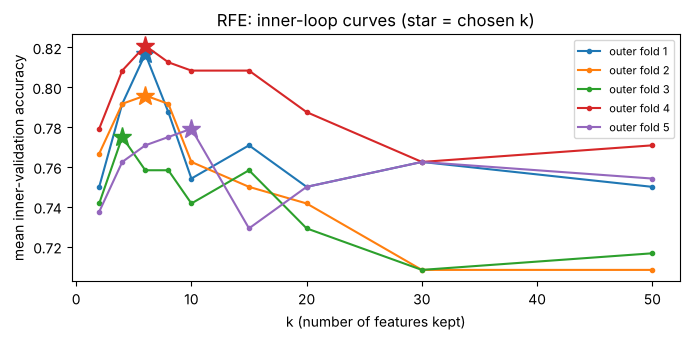

k chosen in each outer fold: [6, 6, 4, 6, 10]


In [ ]:
plt.figure(figsize=(7, 3.5))
for fold, (curve, best) in enumerate(zip(rfe["inner_curves"], rfe["chosen"]), start=1):
    ks = list(curve.keys())
    accs = list(curve.values())
    line, = plt.plot(ks, accs, marker="o", ms=3, label=f"outer fold {fold}")
    plt.plot(best, curve[best], marker="*", ms=14, color=line.get_color())
plt.xlabel("k (number of features kept)")
plt.ylabel("mean inner-validation accuracy")
plt.title("RFE: inner-loop curves (star = chosen k)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

print("k chosen in each outer fold:", rfe["chosen"])

Each training set produces a slightly different curve and a different peak. Read the
**shape**, not the peak: if a region of the curve is flat, any k in it is as good as any
other, and the smallest one gives a simpler model. (A common refinement is to choose the
smallest k whose score is within one standard error of the best.)

The value at the peak is **not** a performance estimate: it is the best of several
candidates, measured on the same folds used to pick it. The performance estimate is the
outer-test accuracy.

## 9. Do the methods agree with each other?

Each method selected one feature set per outer fold. If feature selection recovered
"the true signal", the sets should mostly agree — with each other, and across folds.
(The variance + correlation filter kept everything, so we leave it out.)

In [ ]:
def jaccard(a, b):
    return len(a & b) / len(a | b)

compared = [r for r in results if r["family"] != "-" and r["method"] != "Filter: variance + correlation"]
short = {r["method"]: r["method"].split(": ")[1] for r in compared}

# between methods: compare the two sets chosen on the SAME outer-training fold, then average
names = [short[r["method"]] for r in compared]
jac = pd.DataFrame(index=names, columns=names, dtype=float)
for a in compared:
    for b in compared:
        jac.loc[short[a["method"]], short[b["method"]]] = np.mean(
            [jaccard(sa, sb) for sa, sb in zip(a["sets"], b["sets"])])
print("mean Jaccard overlap between methods (same training fold)\n")
print(jac.round(2).to_string())

# within a method: how similar are its 5 sets to each other?
print("\nmean Jaccard of each method with ITSELF across the 5 outer folds")
for r in compared:
    s = r["sets"]
    pairs = [jaccard(s[i], s[j]) for i in range(len(s)) for j in range(i + 1, len(s))]
    print(f"  {short[r['method']]:28s} {np.mean(pairs):.2f}")

mean Jaccard overlap between methods (same training fold)

                        mutual information   RFE  L1 logistic regression  RF importance
mutual information                    1.00  0.36                    0.25           0.53
RFE                                   0.36  1.00                    0.48           0.44
L1 logistic regression                0.25  0.48                    1.00           0.36
RF importance                         0.53  0.44                    0.36           1.00

mean Jaccard of each method with ITSELF across the 5 outer folds
  mutual information           0.42
  RFE                          0.55
  L1 logistic regression       0.50
  RF importance                0.76


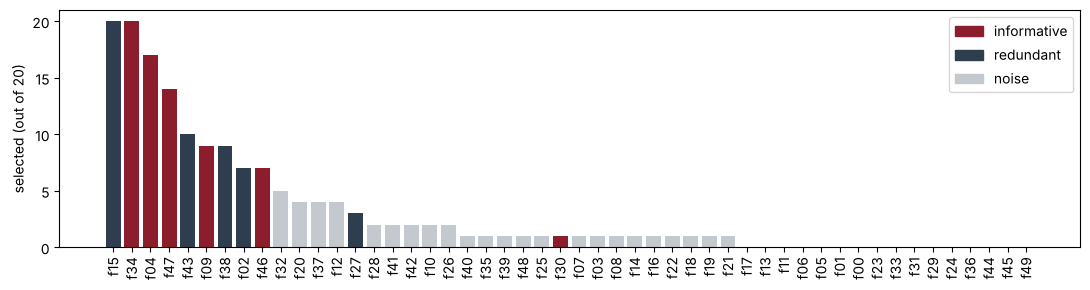

selected in all 20 selections: ['f15', 'f34']
never selected                : ['f00', 'f01', 'f05', 'f06', 'f11', 'f13', 'f17', 'f23', 'f24', 'f29', 'f31', 'f33', 'f36', 'f44', 'f45', 'f49']
roles of the never-selected   : ['noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise', 'noise']


In [ ]:
# how often each feature is selected: 4 methods x 5 folds = 20 selections
n_selections = len(compared) * outer_cv.get_n_splits()
counts = pd.Series(0, index=feature_names)
for r in compared:
    for s in r["sets"]:
        for f in s:
            counts[f] += 1

order = counts.sort_values(ascending=False).index
colors = {"informative": "#8C1D2C", "redundant": "#2F3E4E", "noise": "#C3C9CE"}
plt.figure(figsize=(11, 3))
plt.bar(order, counts[order],
        color=[colors[true_role[feature_names == f][0]] for f in order])
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=role) for role, c in colors.items()])
plt.ylabel(f"selected (out of {n_selections})")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

always = list(counts[counts == n_selections].index)
never = list(counts[counts == 0].index)
print(f"selected in all {n_selections} selections: {always}")
print(f"never selected                : {never}")
print("roles of the never-selected   :", [str(true_role[feature_names == f][0]) for f in never])

The methods agree only partly, and the colours show why. Selection is unstable whenever
features are correlated: the redundant features carry the *same* information as the
informative ones, so a method can take either and score the same. Small changes in the
data — or just a different algorithm — flip the choice.

**Consequences for your project report:**

- Never present "the 10 important features" as a biological finding from one run.
- Report **selection frequency** across folds or bootstrap resamples, as in the plot
  above; features picked in 90 % of resamples mean something, features picked in 40 % do not.
- If you need stability, prefer Elastic Net over pure Lasso: the L2 part keeps
  correlated features together instead of picking one at random.

## 10. Why the same method looks modest here and essential elsewhere

Everything above used a **linear** model. A linear model handles irrelevant features
gracefully: it shrinks their coefficients and moves on.

Distance- and kernel-based models cannot do that. Every noise dimension adds to the
distance between points, so the signal gets diluted — the classic curse of
dimensionality. We repeat the Random-Forest selection, with exactly the same nested
protocol, but now the classifier is an **RBF-kernel SVM** (default C and gamma).

In [ ]:
def new_svm():
    return SVC(kernel="rbf", C=1.0, gamma="scale")

svm_all = nested_cv("RBF SVM, all features", "-", select_all, ["all"],
                    new_model=new_svm, store=False)
svm_rf  = nested_cv("RBF SVM, RF top-k", "embedded", select_rf, K_GRID,
                    new_model=new_svm, store=False)

gain_lr  = rf["accuracy"] - baseline["accuracy"]
gain_svm = svm_rf["accuracy"] - svm_all["accuracy"]
print(f"Logistic regression: all {baseline['accuracy']:.3f} -> RF top-k {rf['accuracy']:.3f}   "
      f"gain {gain_lr:+.3f}")
print(f"RBF SVM            : all {svm_all['accuracy']:.3f} -> RF top-k {svm_rf['accuracy']:.3f}   "
      f"gain {gain_svm:+.3f}")

  outer fold 1: chosen setting = all    features kept = 50   test accuracy = 0.800
  outer fold 2: chosen setting = all    features kept = 50   test accuracy = 0.867
  outer fold 3: chosen setting = all    features kept = 50   test accuracy = 0.833
  outer fold 4: chosen setting = all    features kept = 50   test accuracy = 0.783
  outer fold 5: chosen setting = all    features kept = 50   test accuracy = 0.900
RBF SVM, all features: 0.837 ± 0.043   (0.0s)



  outer fold 1: chosen setting = 10     features kept = 10   test accuracy = 0.967


  outer fold 2: chosen setting = 10     features kept = 10   test accuracy = 0.933


  outer fold 3: chosen setting = 10     features kept = 10   test accuracy = 0.950


  outer fold 4: chosen setting = 10     features kept = 10   test accuracy = 0.867


  outer fold 5: chosen setting = 8      features kept =  8   test accuracy = 0.933
RBF SVM, RF top-k: 0.930 ± 0.034   (33.2s)

Logistic regression: all 0.767 -> RF top-k 0.810   gain +0.043
RBF SVM            : all 0.837 -> RF top-k 0.930   gain +0.093


Same data, same folds, same selector: only the final model changes.

The lesson is not "SVMs are better". It is that **the value of feature selection is a
property of the model you feed, not of the dataset alone.** Before deciding how much
effort to spend on selection, ask what the downstream model does with irrelevant inputs:

| model | tolerance to noise features | is selection worth it? |
|---|---|---|
| linear / L2-regularised | high — shrinks the weights | modest gain, do it for interpretability |
| L1 / Elastic Net | selects by construction | already handled |
| trees, Random Forest | fairly high — ignores useless splits | mainly for speed and interpretability |
| kNN, RBF-SVM, any distance-based | **low** — every noise dimension dilutes the metric | **yes, large gains** |
| neural networks on small data | low | yes, or use strong regularisation |

## 11. Three ways to get the evaluation wrong

We now build a dataset with **no signal whatsoever**: 200 samples, 2000 random
features, random labels. Any honest estimate must land near 0.50. We select features by
their absolute correlation with the label, and compare three protocols:

1. **Selection outside the CV** — rank the features on *all* the data, keep the top 20,
   then cross-validate.
2. **Selection inside the folds, k chosen on the test folds** — for each candidate k,
   run a 5-fold CV with selection done properly inside each training fold; then report the
   score of the best k. (This is what you do if you read the peak of an RFECV curve as
   your result.)
3. **Nested CV** — k is chosen by the inner loop, the score comes from the outer-test folds.

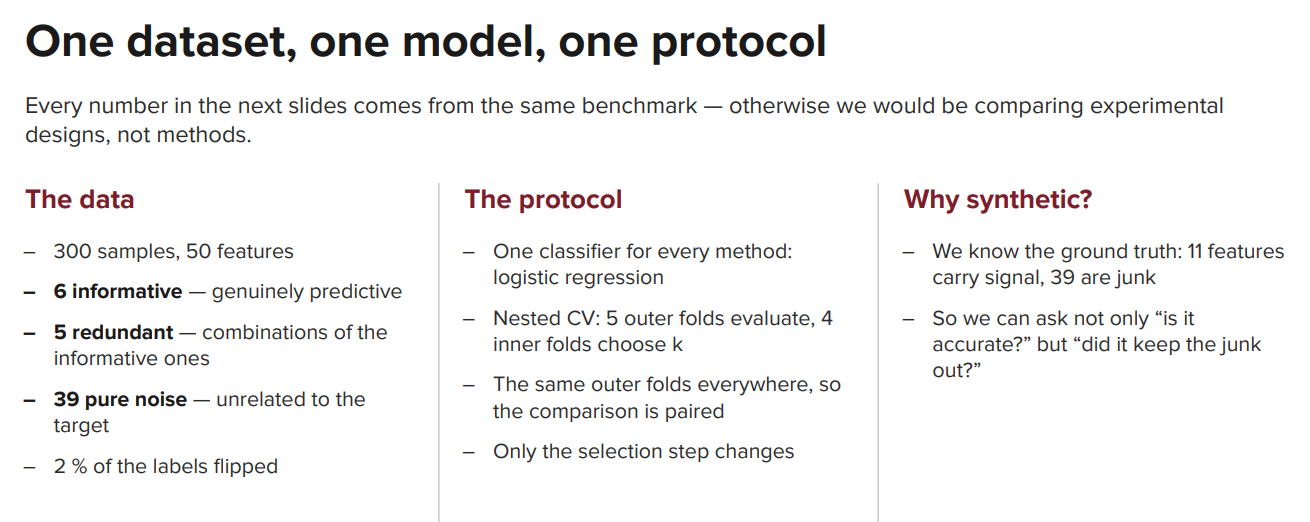

In [ ]:
rng = np.random.RandomState(0)
X_noise = rng.randn(200, 2000)
y_noise = np.random.RandomState(1).randint(0, 2, 200)
cv_noise = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
K_NOISE = [1, 2, 5, 10, 20, 50, 100]

def select_corr(X_train, y_train, k):
    # absolute Pearson correlation of every column with the label, keep the k highest
    scores = np.array([abs(np.corrcoef(X_train[:, j], y_train)[0, 1])
                       for j in range(X_train.shape[1])])
    return np.argsort(scores)[::-1][:k]

# --- 1. WRONG: selection on all the data, then CV ------------------------------------
cols = select_corr(X_noise, y_noise, 20)
accs = [train_and_test(X_noise[tr][:, cols], y_noise[tr], X_noise[te][:, cols], y_noise[te])
        for tr, te in cv_noise.split(X_noise, y_noise)]
wrong_1 = np.mean(accs)

# --- 2. WRONG: selection inside the folds, but k picked by looking at the test folds ---
cv_score = {}
for k in K_NOISE:
    accs = []
    for tr, te in cv_noise.split(X_noise, y_noise):
        cols = select_corr(X_noise[tr], y_noise[tr], k)
        accs.append(train_and_test(X_noise[tr][:, cols], y_noise[tr],
                                   X_noise[te][:, cols], y_noise[te]))
    cv_score[k] = np.mean(accs)
best_k = max(cv_score, key=cv_score.get)
wrong_2 = cv_score[best_k]

# --- 3. RIGHT: nested CV (same building blocks as before) ------------------------------
accs = []
for tr, te in cv_noise.split(X_noise, y_noise):
    k, _ = choose_setting(select_corr, K_NOISE, X_noise[tr], y_noise[tr])
    cols = select_corr(X_noise[tr], y_noise[tr], k)
    accs.append(train_and_test(X_noise[tr][:, cols], y_noise[tr],
                               X_noise[te][:, cols], y_noise[te]))
right = np.mean(accs)

print(f"1. selection outside the CV           : {wrong_1:.3f}   <-- pure illusion")
print(f"2. inside the folds, k picked on test : {wrong_2:.3f}   (best k = {best_k})")
print(f"3. nested CV                          : {right:.3f}")
print(f"   the truth                          : 0.500")

1. selection outside the CV           : 0.825   <-- pure illusion
2. inside the folds, k picked on test : 0.635   (best k = 2)
3. nested CV                          : 0.500
   the truth                          : 0.500


**Protocol 1** is the most dangerous: with 2000 random features and 200 samples, some
features correlate with the labels by pure chance. Choosing them *while looking at the
test samples* leaks the answer into the selection step, and the classifier then
"confirms" a pattern that the selection step planted. This is one of the most common
reasons a published biomarker signature fails to replicate (Ambroise & McLachlan,
*PNAS* 2002) — and protein features (PSSM columns, 1024-dimensional embeddings) are
exactly the high-dimensional regime where it bites.

**Protocol 2** is subtler. Every single score in it is honest, but reporting the *best*
of several honest scores is not: the maximum of several noisy numbers is biased upwards.
The more candidates you try, the larger the bias.

**Protocol 3** keeps choice and evaluation apart, and lands where it should. A single
5-fold run still wobbles by a few points around 0.50: with 40 test samples per fold,
that is normal.

### How optimistic is protocol 2 on our dataset?

On the 50-feature dataset we can compare, for every method, the nested estimate with the
"best k on the same folds" estimate.

In [ ]:
def best_k_on_same_folds(select, grid):
    # protocol 2: CV for every setting (selection inside the folds), report the best one
    mean_acc = {}
    for setting in grid:
        accs = []
        for tr, te in outer_cv.split(X, y):
            cols = select(X[tr], y[tr], setting)
            accs.append(train_and_test(X[tr][:, cols], y[tr], X[te][:, cols], y[te]))
        mean_acc[setting] = np.mean(accs)
    best = max(mean_acc, key=mean_acc.get)
    return best, mean_acc[best]

opt_rows = []
for r in results:
    if len(r["grid"]) == 1:
        continue
    best, score = best_k_on_same_folds(r["select"], r["grid"])
    opt_rows.append({"method": r["method"], "nested CV": r["accuracy"],
                     "best setting on the same folds": score, "setting": str(best),
                     "optimism": score - r["accuracy"]})
opt = pd.DataFrame(opt_rows)
opt.style.format({"nested CV": "{:.3f}", "best setting on the same folds": "{:.3f}",
                  "optimism": "{:+.3f}"})

,method,nested CV,best setting on the same folds,setting,optimism
0,Filter: mutual information,0.787,0.807,8,+0.020
1,Wrapper: RFE,0.793,0.797,4,+0.003
2,Embedded: L1 logistic regression,0.787,0.797,0.05,+0.010
3,Embedded: RF importance,0.810,0.820,6,+0.010


With 50 features, 300 samples and a handful of candidate settings, the optimism is
small. It grows with the number of features, the number of candidate settings, and the
smallness of the dataset — and in real projects you tune k, C and gamma together.
Nested CV costs more computation, but its number is the one you can defend.

## 12. The same thing, the scikit-learn way

Everything we wrote by hand has a ready-made equivalent:

| our code | scikit-learn |
|---|---|
| `train_and_test` with a scaler fitted on training data | `Pipeline([("scale", StandardScaler()), ..., ("clf", model)])` |
| a `select(X, y, k)` function | a selector step such as `SelectKBest(score_func, k=...)` |
| `choose_setting` (inner loop) | `GridSearchCV(pipeline, {"select__k": K_GRID}, cv=inner_cv)` |
| `nested_cv` (outer loop) | `cross_val_score(grid_search, X, y, cv=outer_cv)` |

Because the selector is a *step of the pipeline*, scikit-learn refits it on every
training fold automatically — the test fold can never leak into it. Let us check that the
library gives exactly the numbers we computed by hand for mutual information.

In [ ]:
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import GridSearchCV, cross_val_score

pipeline = Pipeline([
    ("scale",  StandardScaler()),
    ("select", SelectKBest(partial(mutual_info_classif, random_state=42))),
    ("clf",    new_logreg()),
])
inner_search = GridSearchCV(pipeline, {"select__k": K_GRID}, cv=inner_cv)   # inner loop
sk_scores = cross_val_score(inner_search, X, y, cv=outer_cv)                # outer loop

print("by hand      :", np.round(mi["fold_accs"], 3), f"-> {mi['accuracy']:.3f}")
print("scikit-learn :", np.round(sk_scores, 3), f"-> {sk_scores.mean():.3f}")

by hand      : [0.8   0.783 0.8   0.767 0.783] -> 0.787
scikit-learn : [0.8   0.783 0.8   0.767 0.783] -> 0.787


Same folds, same choices, same numbers. Use the short version in your projects — but now
you know what it does.

## 13. What to take away

1. **Choosing is part of the method.** Any setting chosen from the data (k, C, gamma…) must
   be chosen inside the training data: inner loop to choose, outer loop to evaluate.
2. **Compare fairly.** One dataset, one model, the same outer folds for every method.
3. **Compare the gain to the noise.** Report mean ± std; gains under one standard
   deviation are not results.
4. **Count the cost.** Inside a nested CV every selection is repeated many times.
5. **Expect disagreement.** Correlated features make selection unstable. Report selection
   frequency, not a single list.
6. **Know your downstream model.** The same selector helps a distance-based model much
   more than a linear one.
7. **Never select, or choose k, while looking at the test data.**

### Exercises

1. Re-run section 1 with `n_informative=3, n_redundant=0, n_features=200`. Does feature
   selection matter more or less? How large does the optimism of protocol 2 become?
2. Replace `new_logreg` with a `KNeighborsClassifier()` in `train_and_test`. Which methods
   change rank, and does the story of section 10 hold?
3. Change `choose_setting` so that it returns the **smallest** k whose score is within one
   standard error of the best. How do `k per fold` and the accuracy change?
4. Use 3 inner folds instead of 4, and a finer `K_GRID` (every k from 1 to 50). Does the
   nested accuracy change? How much longer does it take, and why?